# SARIMAX — Seasonal Autoregressive Integrated Moving Average with Exogenous Factors
**Model**: `SARIMAX`  
**Milestone**: M6a — Linear & Statistical Models  
**Evaluated Problems**:
- **D1**: Karnataka Grid Demand (1-hour ahead)
- **D24**: Karnataka Grid Demand (24-hours ahead / Day-Ahead)
- **S1**: Pavagada Solar Generation (1-hour ahead)
- **S24**: Pavagada Solar Generation (24-hours ahead)

### Purpose & Theoretical Formulation
SARIMAX integrates autoregressive dynamics, differencing for non-stationarity, and moving average error correction, augmented with exogenous meteorological drivers (`temperature_2m_c`, `poa_irradiance_wm2`, calendar cyclical features). As noted in the roadmap, SARIMAX is evaluated on a recent representative training window (1 full calendar year) to capture current diurnal state transitions efficiently.


In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

project_root = Path.cwd().parent.parent if Path.cwd().name == "linear_statistical" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config
import src.models_stat as ms

print("Project root successfully linked:", project_root)


Project root successfully linked: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT


## 1. Train SARIMAX on Problems

In [2]:
problems = ["D1", "D24", "S1", "S24"]
results = []

for pid in problems:
    res = ms.train_and_eval_sarimax(problem_id=pid, train_window=8760, order=(1, 0, 1))
    ms.plot_model_diagnostics(res)
    results.append(res)


LOADING PROCESSED DATASET FOR PROBLEM: D1
Target: demand_mw | Horizon: 1h
Using Scaled Features: False
• Training Features Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_train_D1.parquet
• Training Target Path:     C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_train_D1.parquet
• Validation Features Path: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_val_D1.parquet
• Validation Target Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_val_D1.parquet
• Test Features Path:       C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_test_D1.parquet (QUARANTINED - NOT TOUCHED)
Loaded Train: 33,480 rows (2021-03-08 00:00:00 to 2024-12-31 23:00:00)
Loaded Val:   8,760 rows (2025-01-01 00:00:00 to 2025-12-31 23:00:00)
Test Available: X_test_D1.parquet (44 features, strictly quarantined)

Training SARIMAX on D1 (order=(1, 0, 1), 5 exogenous variables)...


Saved SARIMAX artifact: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\models\sarimax_D1.joblib


LOADING PROCESSED DATASET FOR PROBLEM: D24
Target: demand_mw | Horizon: 24h
Using Scaled Features: False
• Training Features Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_train_D24.parquet
• Training Target Path:     C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_train_D24.parquet
• Validation Features Path: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_val_D24.parquet
• Validation Target Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_val_D24.parquet
• Test Features Path:       C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_test_D24.parquet (QUARANTINED - NOT TOUCHED)
Loaded Train: 33,480 rows (2021-03-08 00:00:00 to 2024-12-31 23:00:00)
Loaded Val:   8,760 rows (2025-01-01 00:00:00 to 2025-12-31 23:00:00)
Test Available: X_test_D24.parquet (41 features, strictly quarantined)

Training SARIMAX on D24 (order=(1, 0, 1), 5 exogenous variables)...


Saved SARIMAX artifact: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\models\sarimax_D24.joblib


LOADING PROCESSED DATASET FOR PROBLEM: S1
Target: solar_power_mw | Horizon: 1h
Using Scaled Features: False
• Training Features Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_train_S1.parquet
• Training Target Path:     C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_train_S1.parquet
• Validation Features Path: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_val_S1.parquet
• Validation Target Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_val_S1.parquet
• Test Features Path:       C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_test_S1.parquet (QUARANTINED - NOT TOUCHED)
Loaded Train: 33,480 rows (2021-03-08 00:00:00 to 2024-12-31 23:00:00)
Loaded Val:   8,760 rows (2025-01-01 00:00:00 to 2025-12-31 23:00:00)
Test Available: X_test_S1.parquet (44 features, strictly quarantined)

Training SARIMAX on S1 (order=(1, 0, 1), 5 exogenous variables)...


Saved SARIMAX artifact: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\models\sarimax_S1.joblib


LOADING PROCESSED DATASET FOR PROBLEM: S24
Target: solar_power_mw | Horizon: 24h
Using Scaled Features: False
• Training Features Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_train_S24.parquet
• Training Target Path:     C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_train_S24.parquet
• Validation Features Path: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_val_S24.parquet
• Validation Target Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_val_S24.parquet
• Test Features Path:       C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_test_S24.parquet (QUARANTINED - NOT TOUCHED)
Loaded Train: 33,480 rows (2021-03-08 00:00:00 to 2024-12-31 23:00:00)
Loaded Val:   8,760 rows (2025-01-01 00:00:00 to 2025-12-31 23:00:00)
Test Available: X_test_S24.parquet (41 features, strictly quarantined)

Training SARIMAX on S24 (order=(1, 0, 1), 5 exogenous variables)...


Saved SARIMAX artifact: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\models\sarimax_S24.joblib


## 2. Validation Metrics Table

In [3]:
metrics_df = ms.save_and_record_results(results, "sarimax")
display(metrics_df)



Saved validation predictions to: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\predictions\sarimax_val_predictions.parquet
Saved validation metrics table to: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\tables\sarimax_val_metrics.csv


,model,problem,target,horizon,rmse,mae,nmae_pct,mape_pct,smape_pct,r2,mbe,skill_vs_persistence,daylight_rmse,daylight_mae,daylight_nmae_pct
0,sarimax,D1,demand_mw,1h,8019.64,7821.87,62.11,61.85,90.46,-13.4452,-7821.72,-1097.03,NaN,NaN,NaN
1,sarimax,D24,demand_mw,24h,8019.64,7821.87,62.11,61.85,90.46,-13.4452,-7821.72,-939.76,NaN,NaN,NaN
2,sarimax,S1,solar_power_mw,1h,53.41,17.54,0.86,NaN,6.60,0.9915,4.94,74.70,75.24,34.82,1.7
3,sarimax,S24,solar_power_mw,24h,53.41,17.54,0.86,NaN,6.60,0.9915,4.94,74.83,75.24,34.82,1.7


## 3. Diagnostic Visualizations


DIAGNOSTIC PLOTS FOR PROBLEM D1


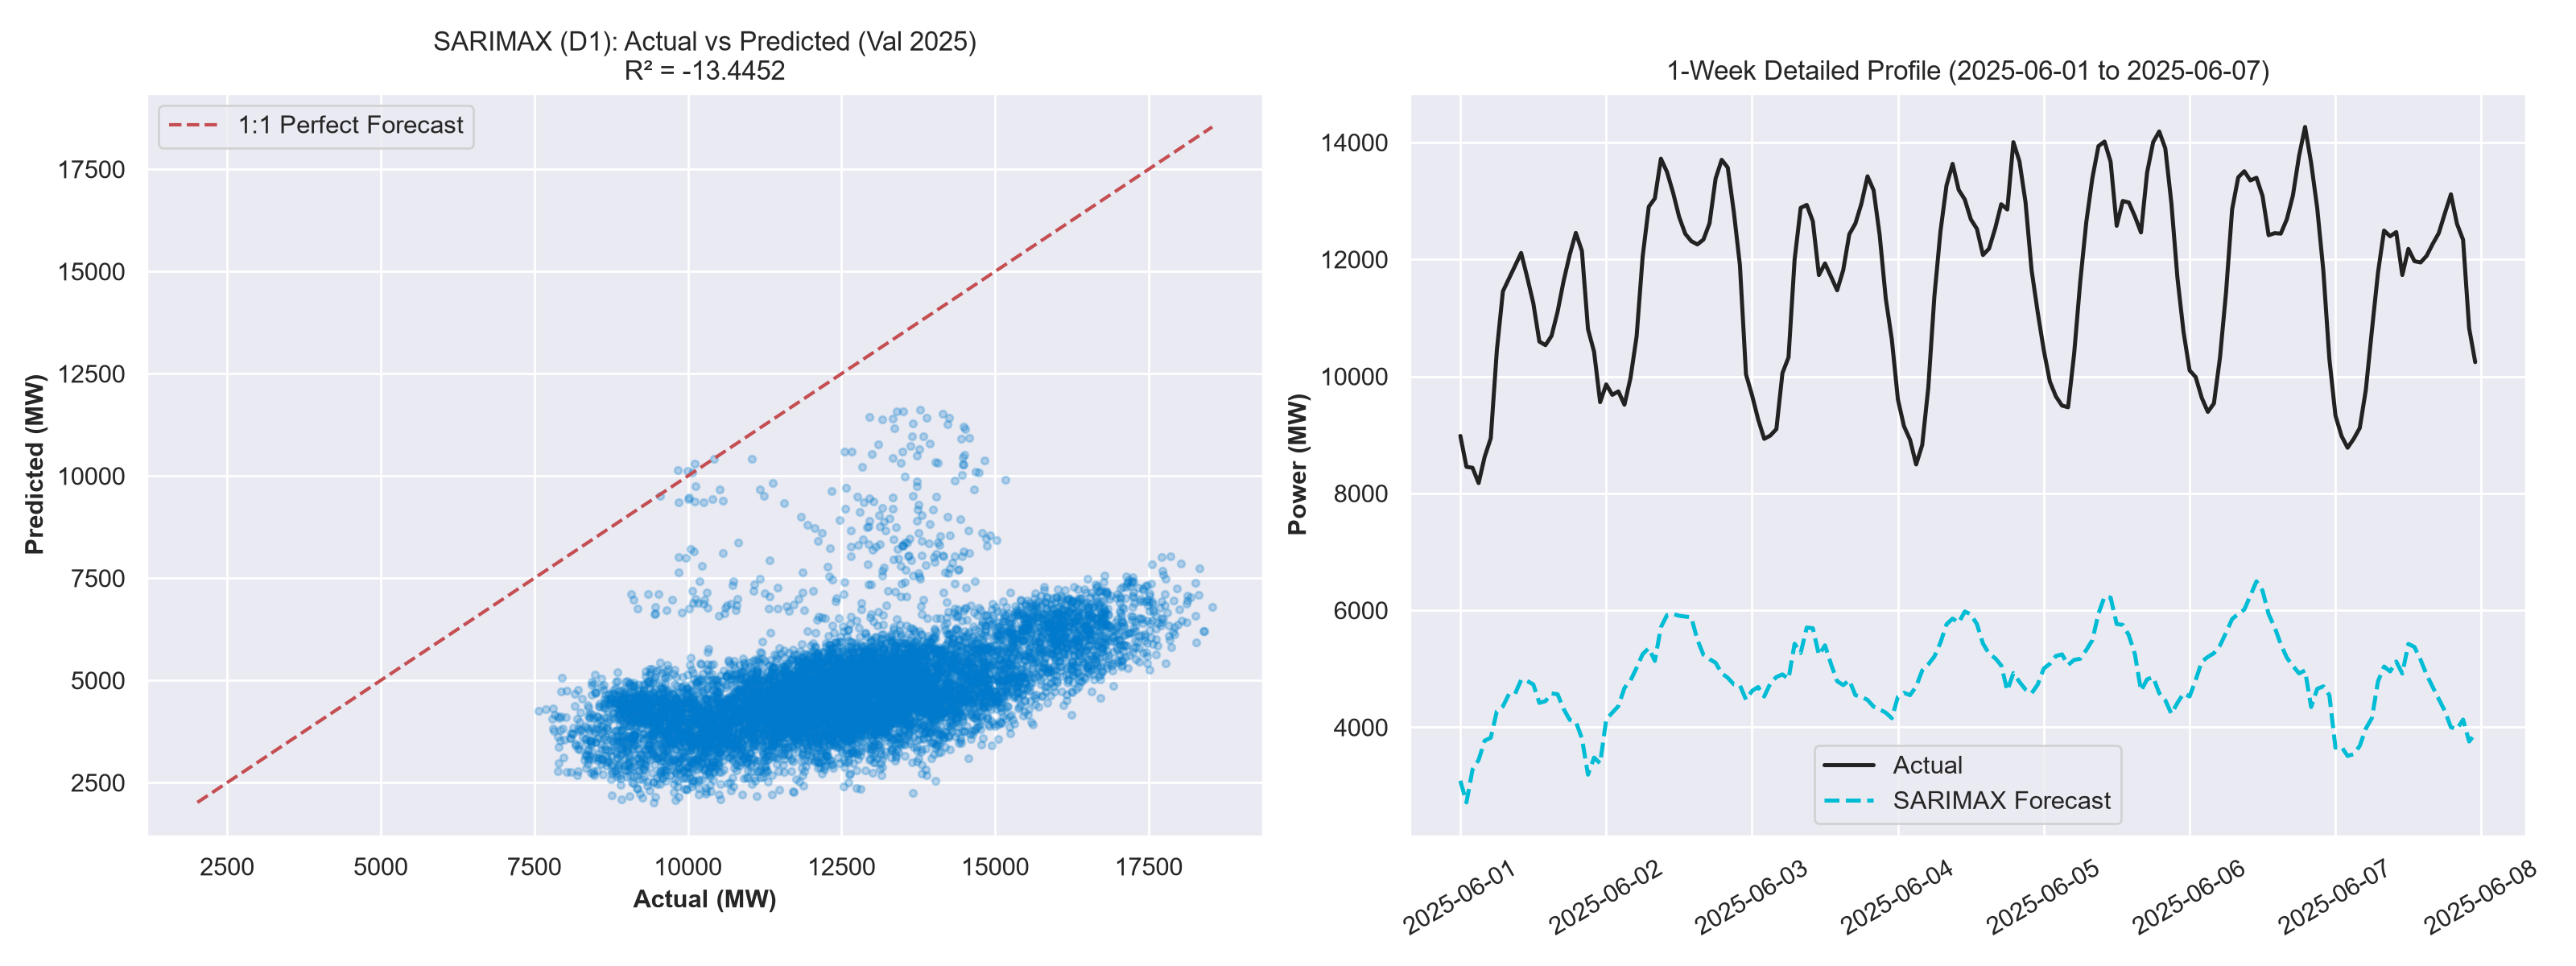

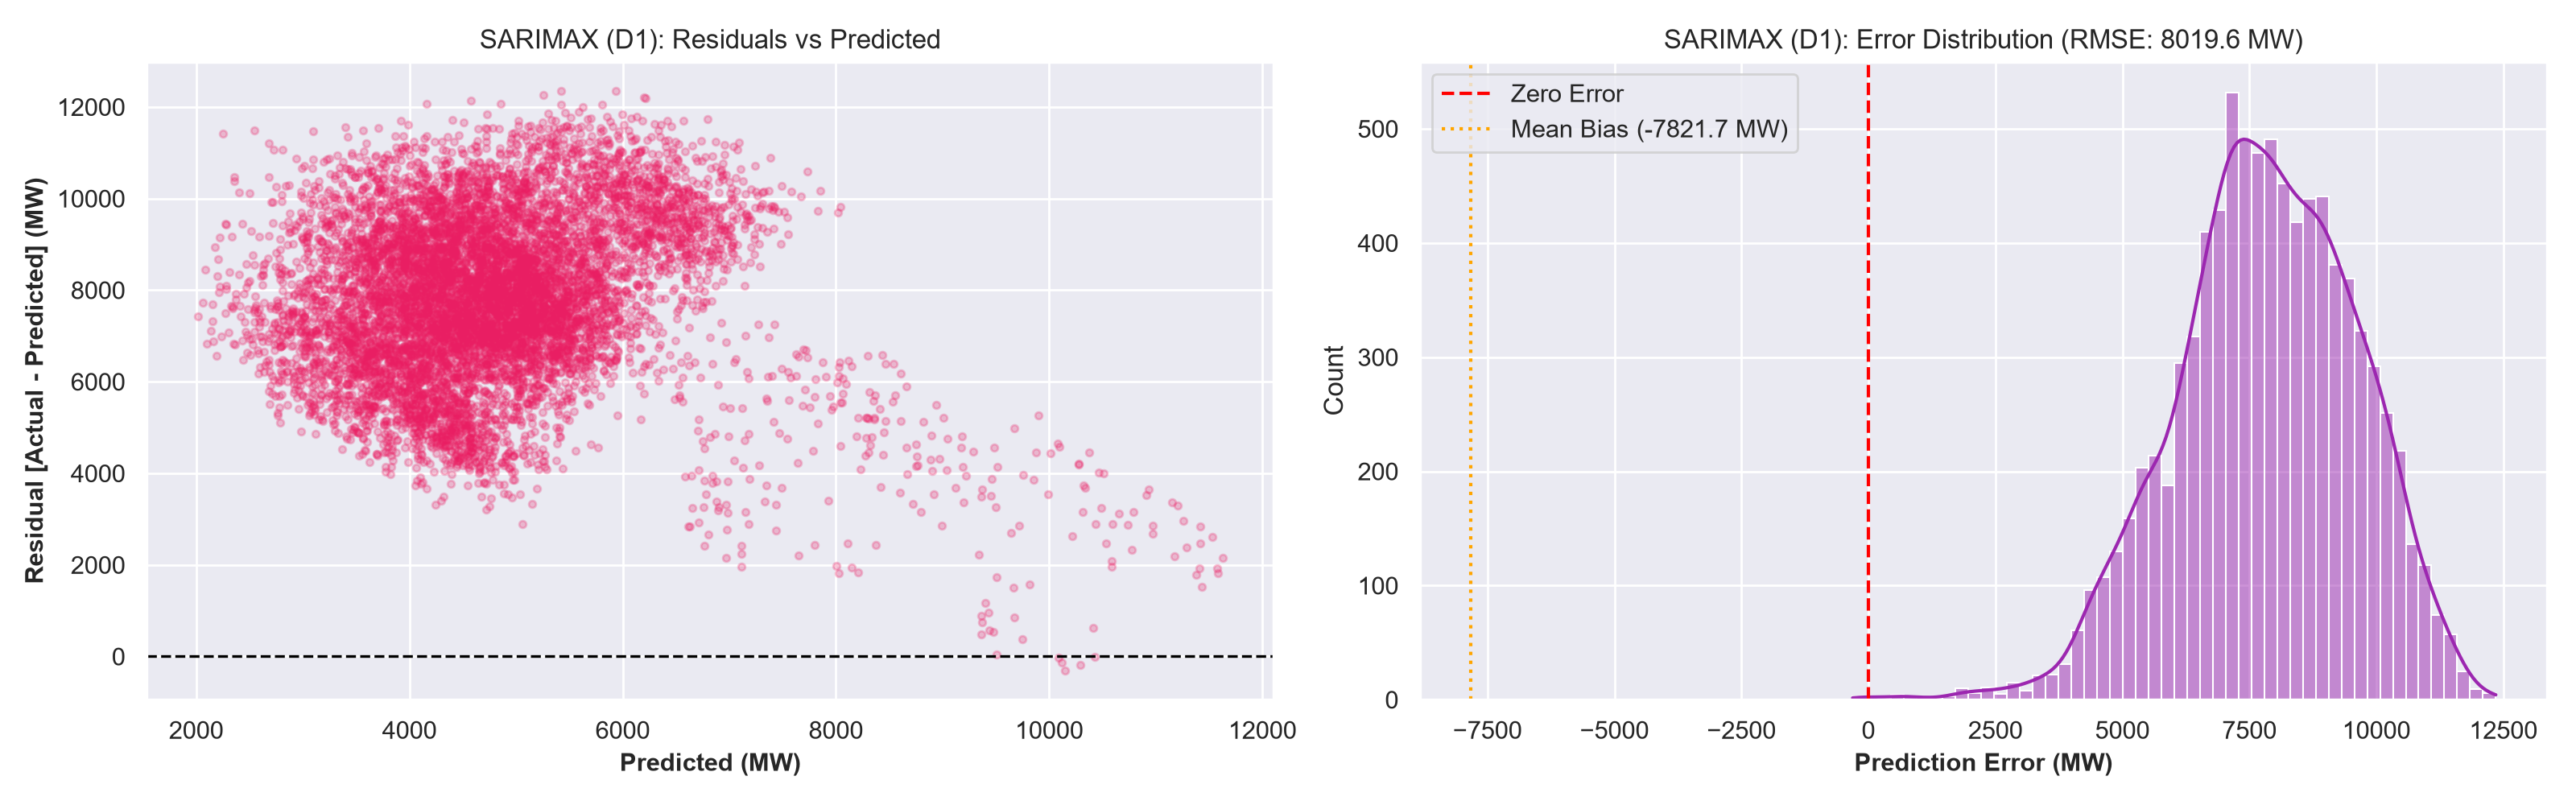


DIAGNOSTIC PLOTS FOR PROBLEM D24


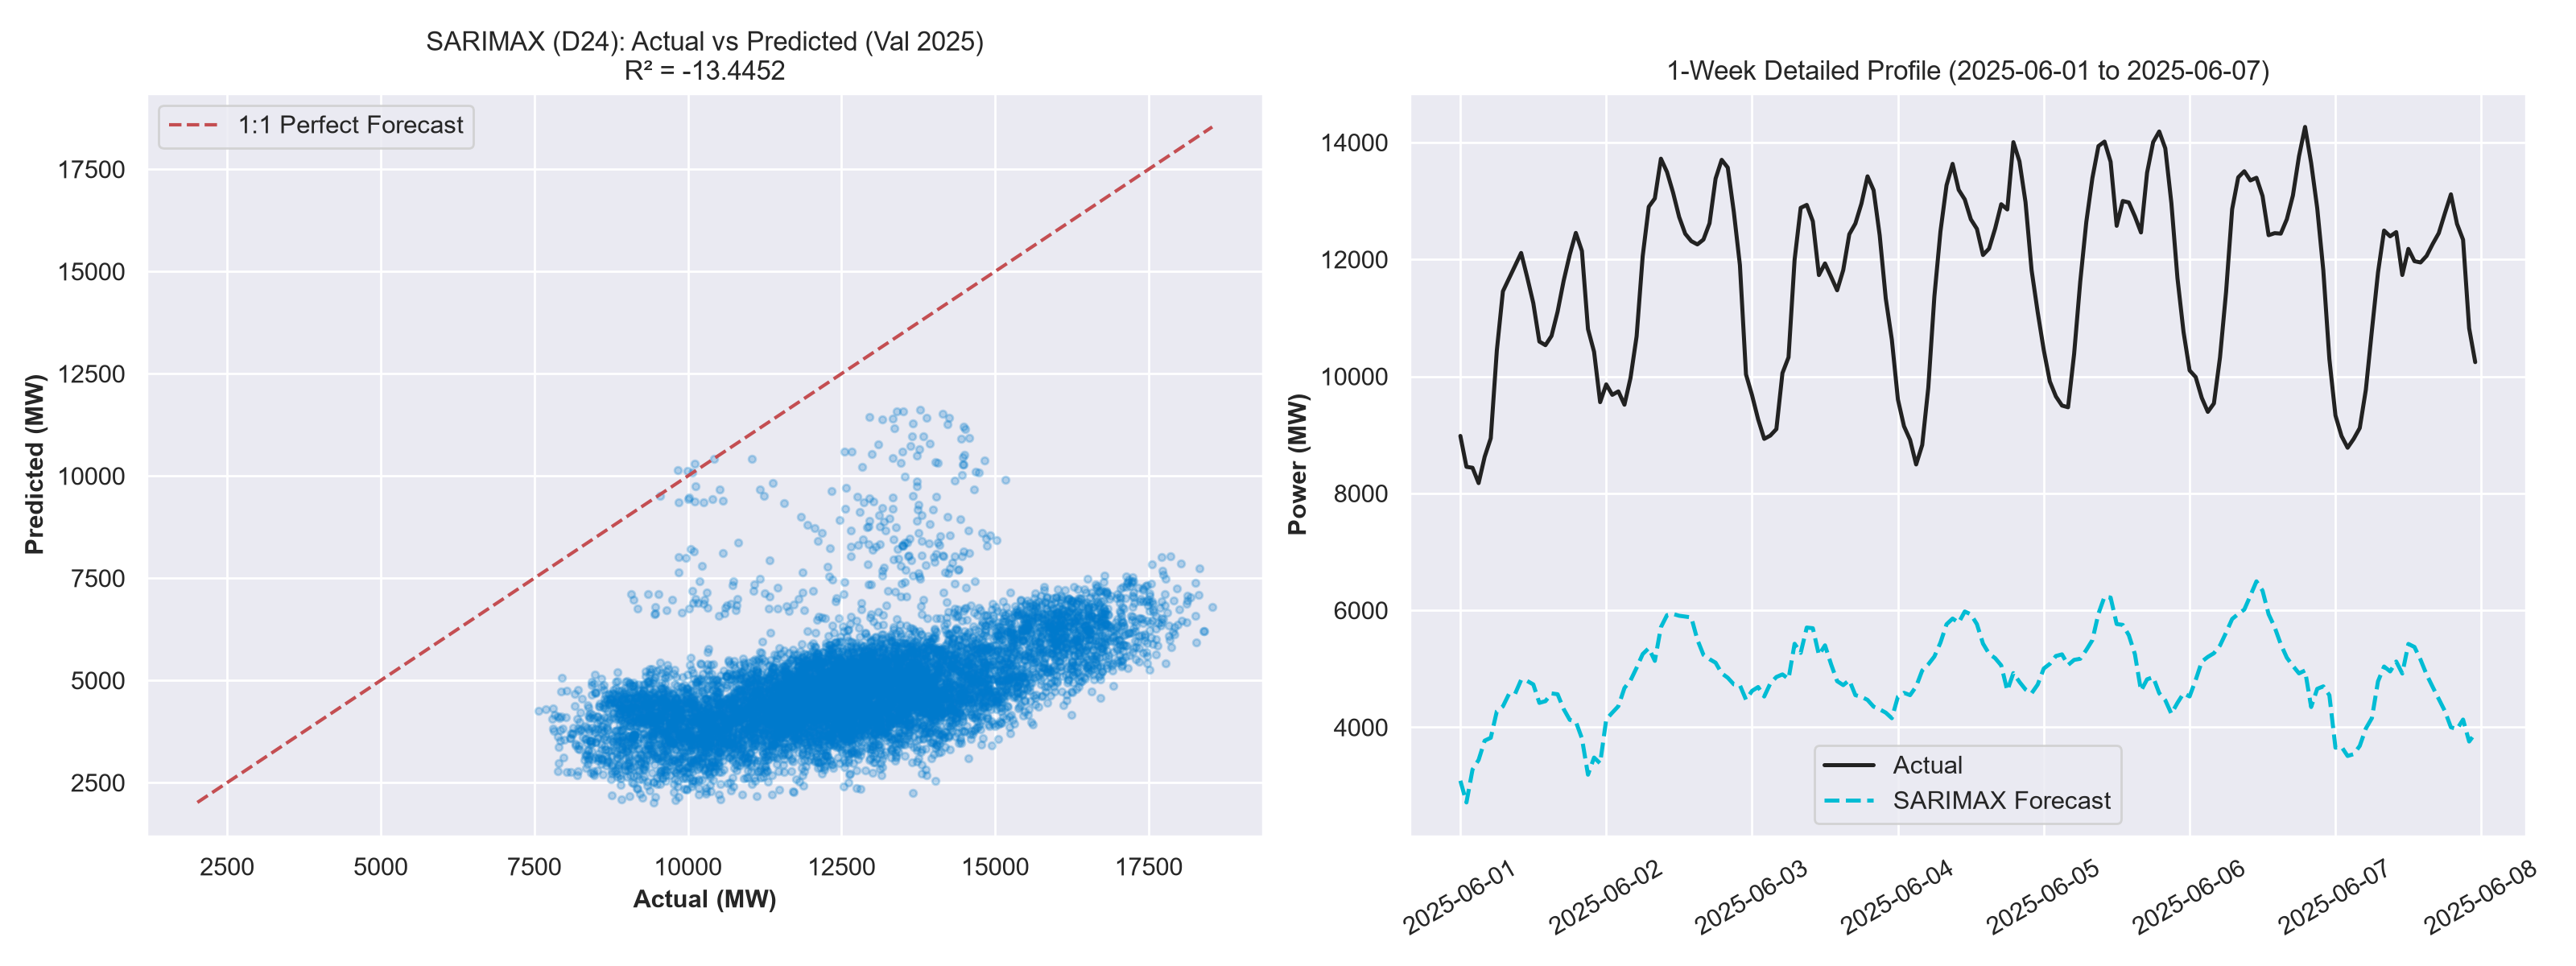

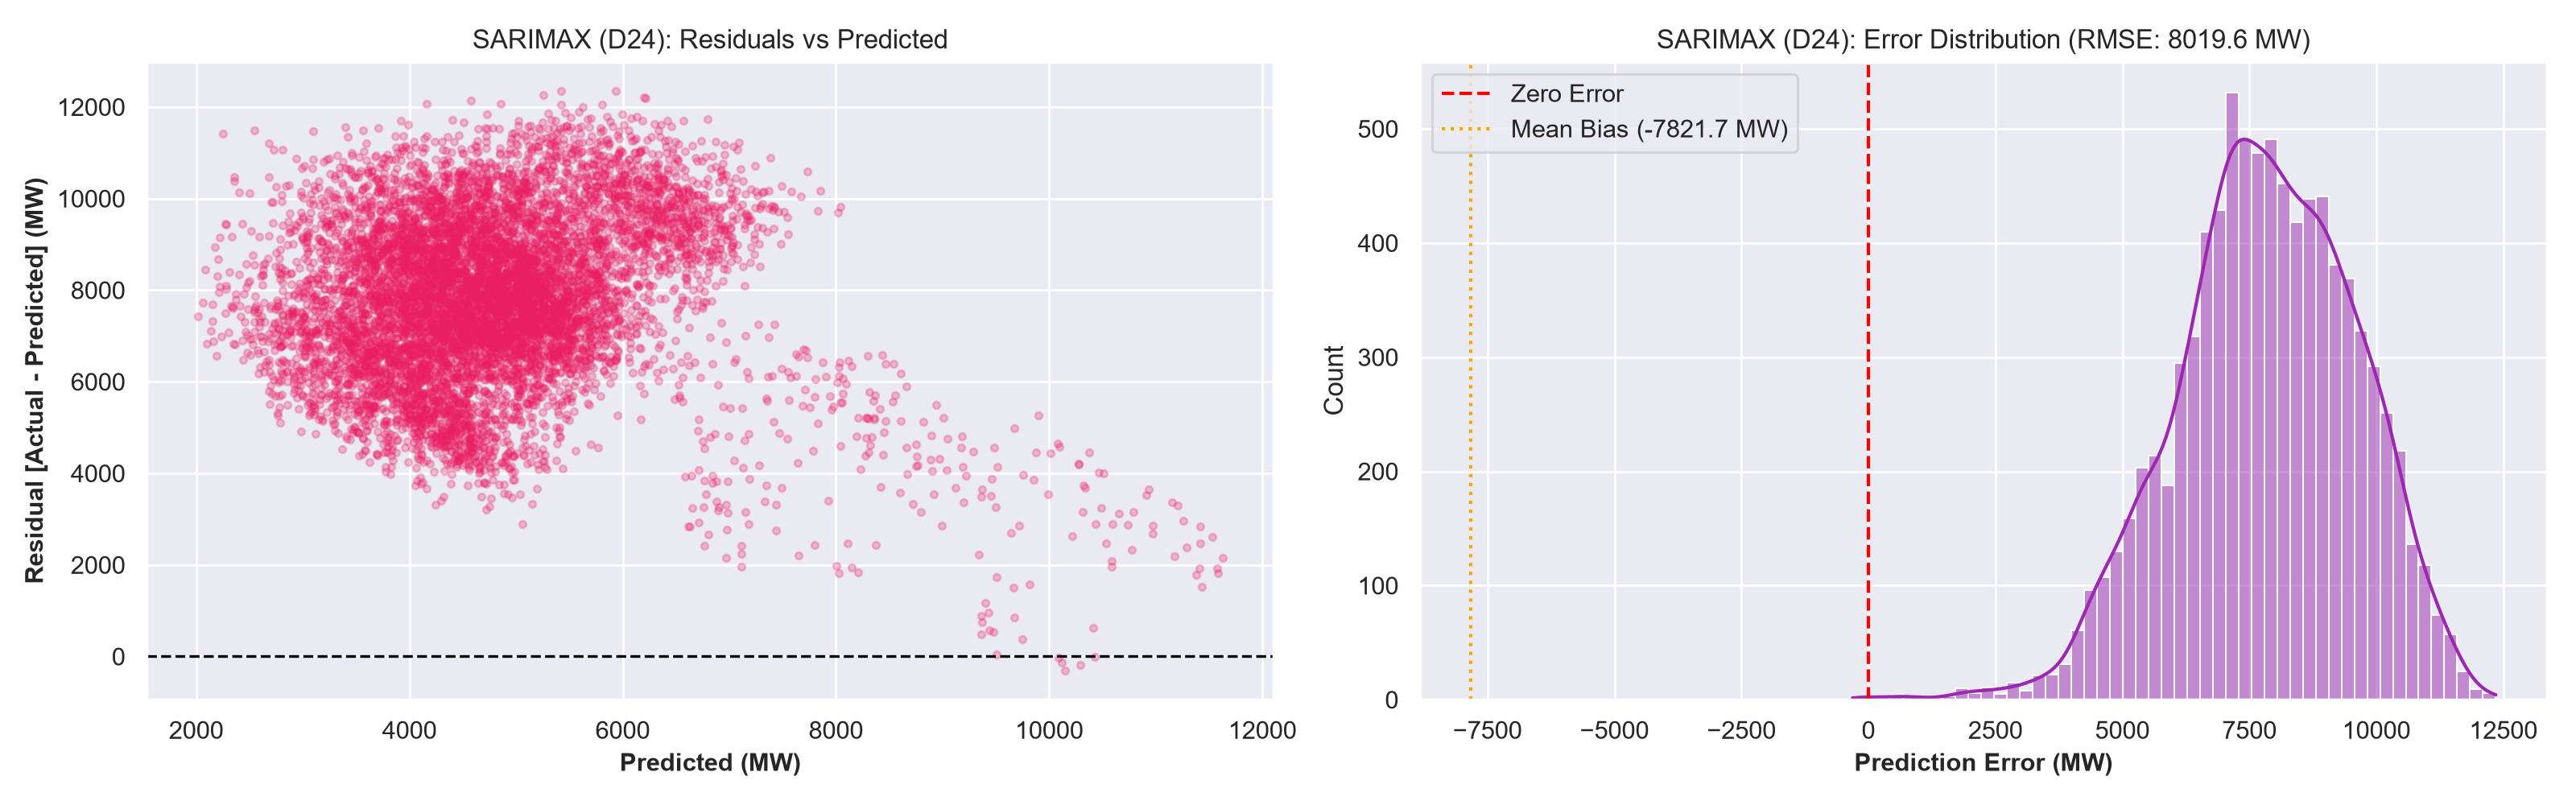


DIAGNOSTIC PLOTS FOR PROBLEM S1


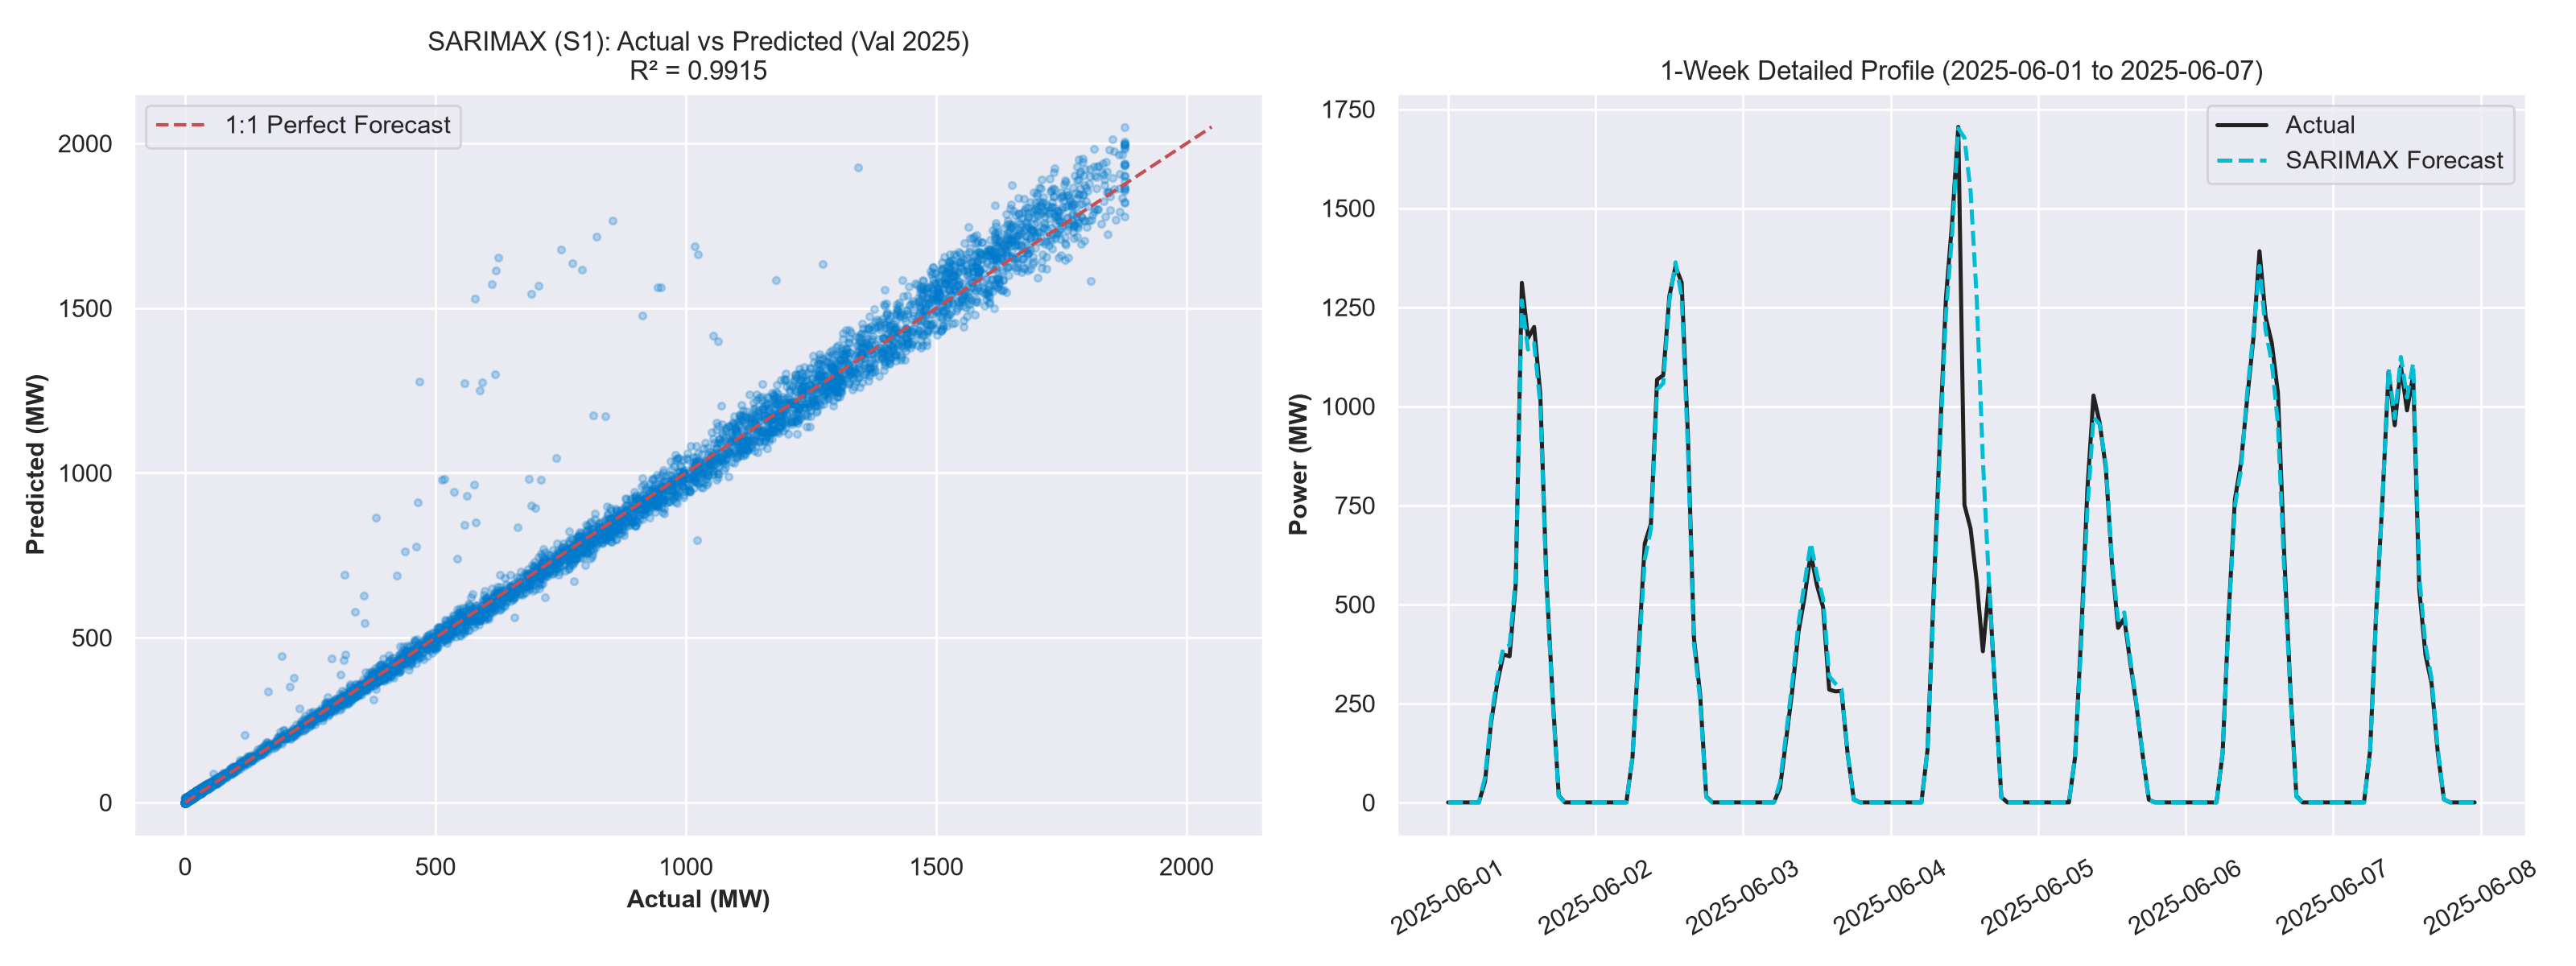

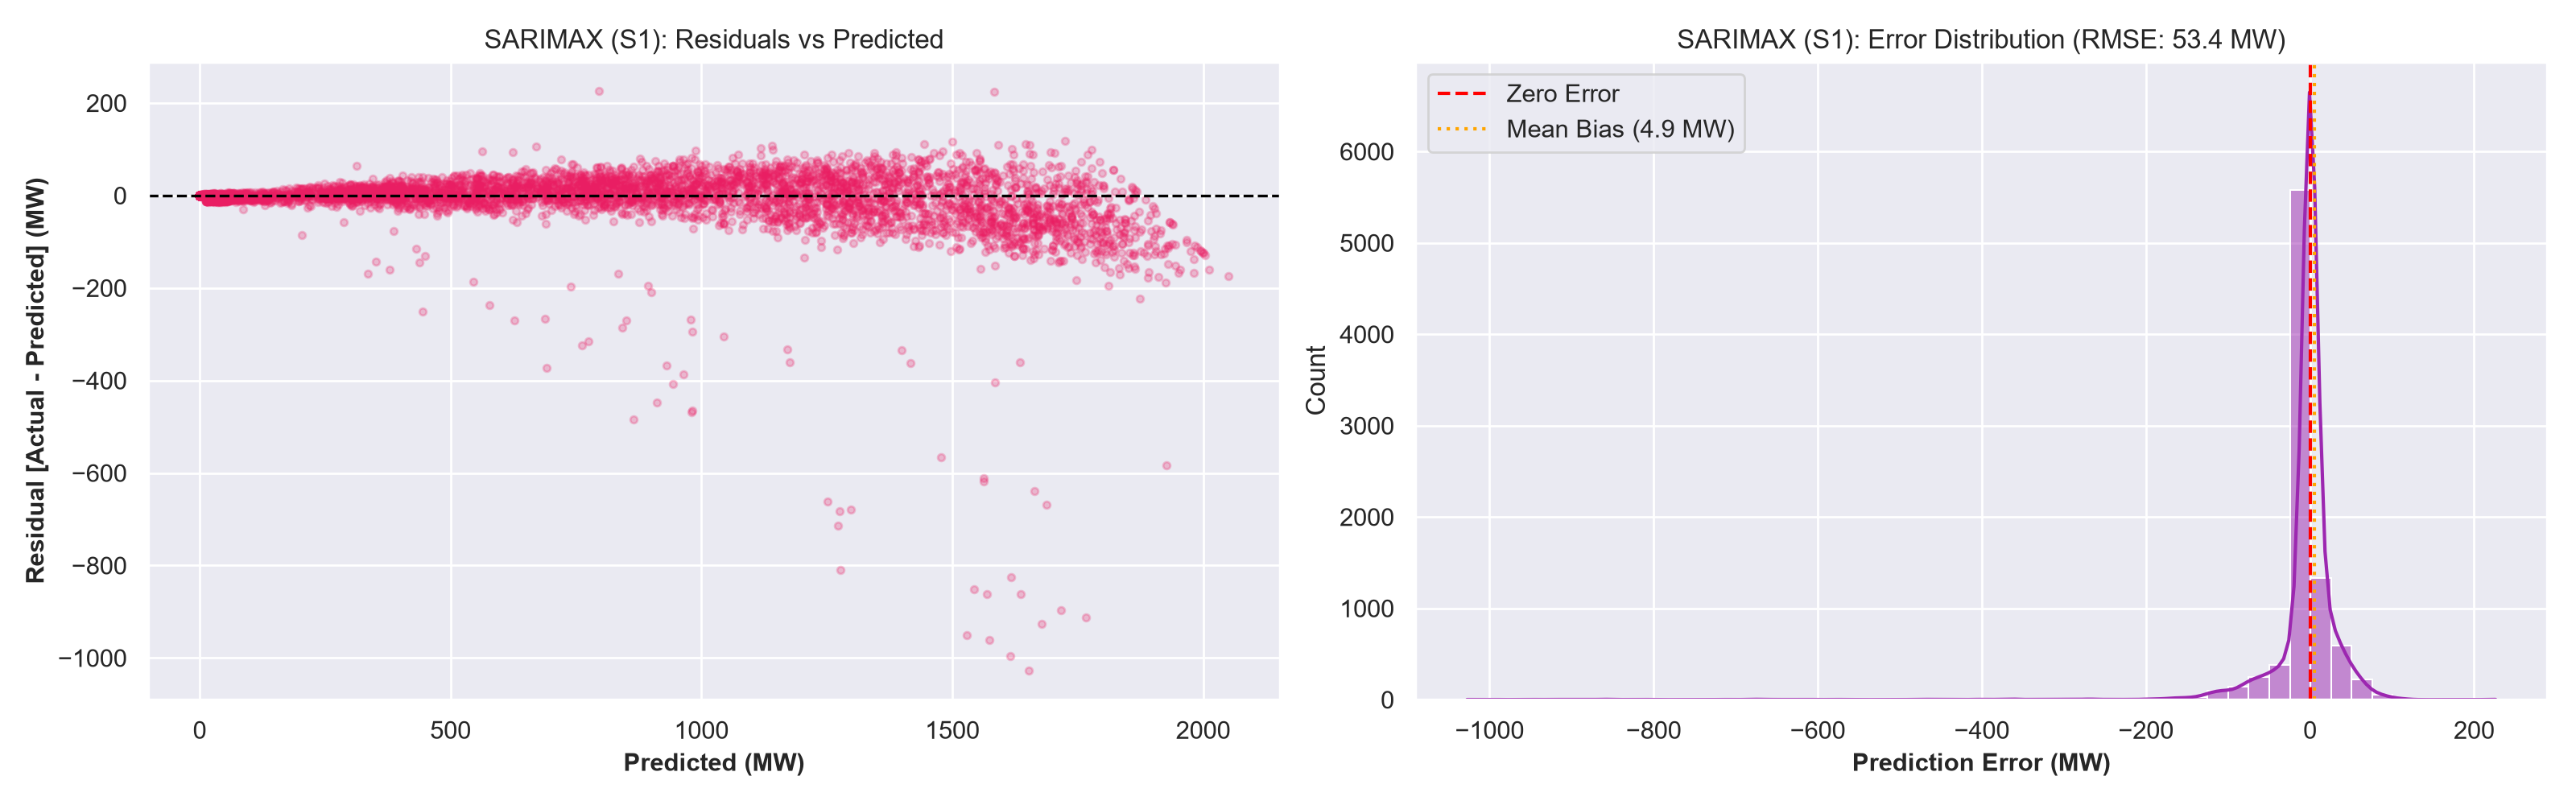


DIAGNOSTIC PLOTS FOR PROBLEM S24


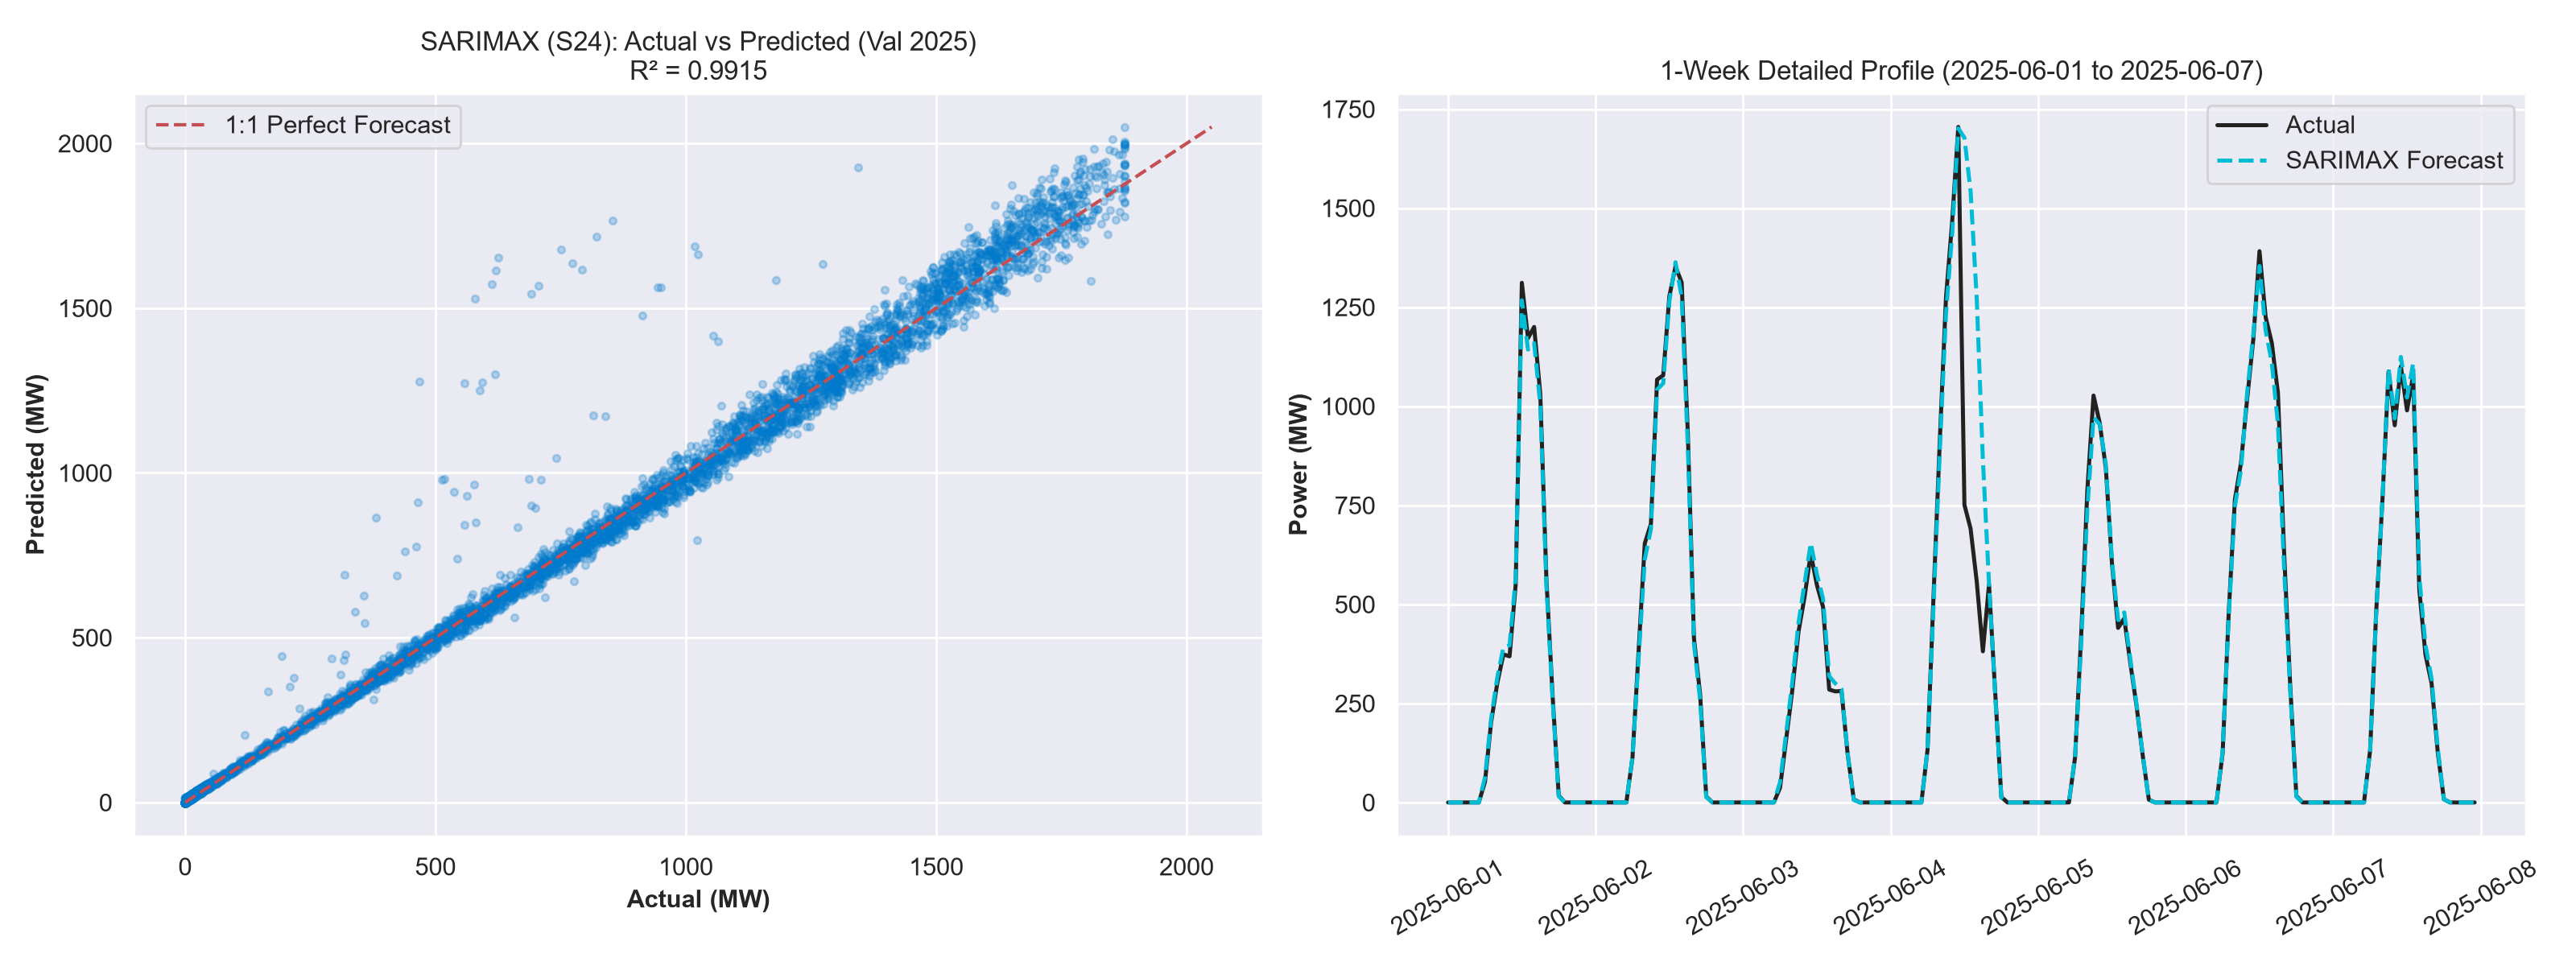

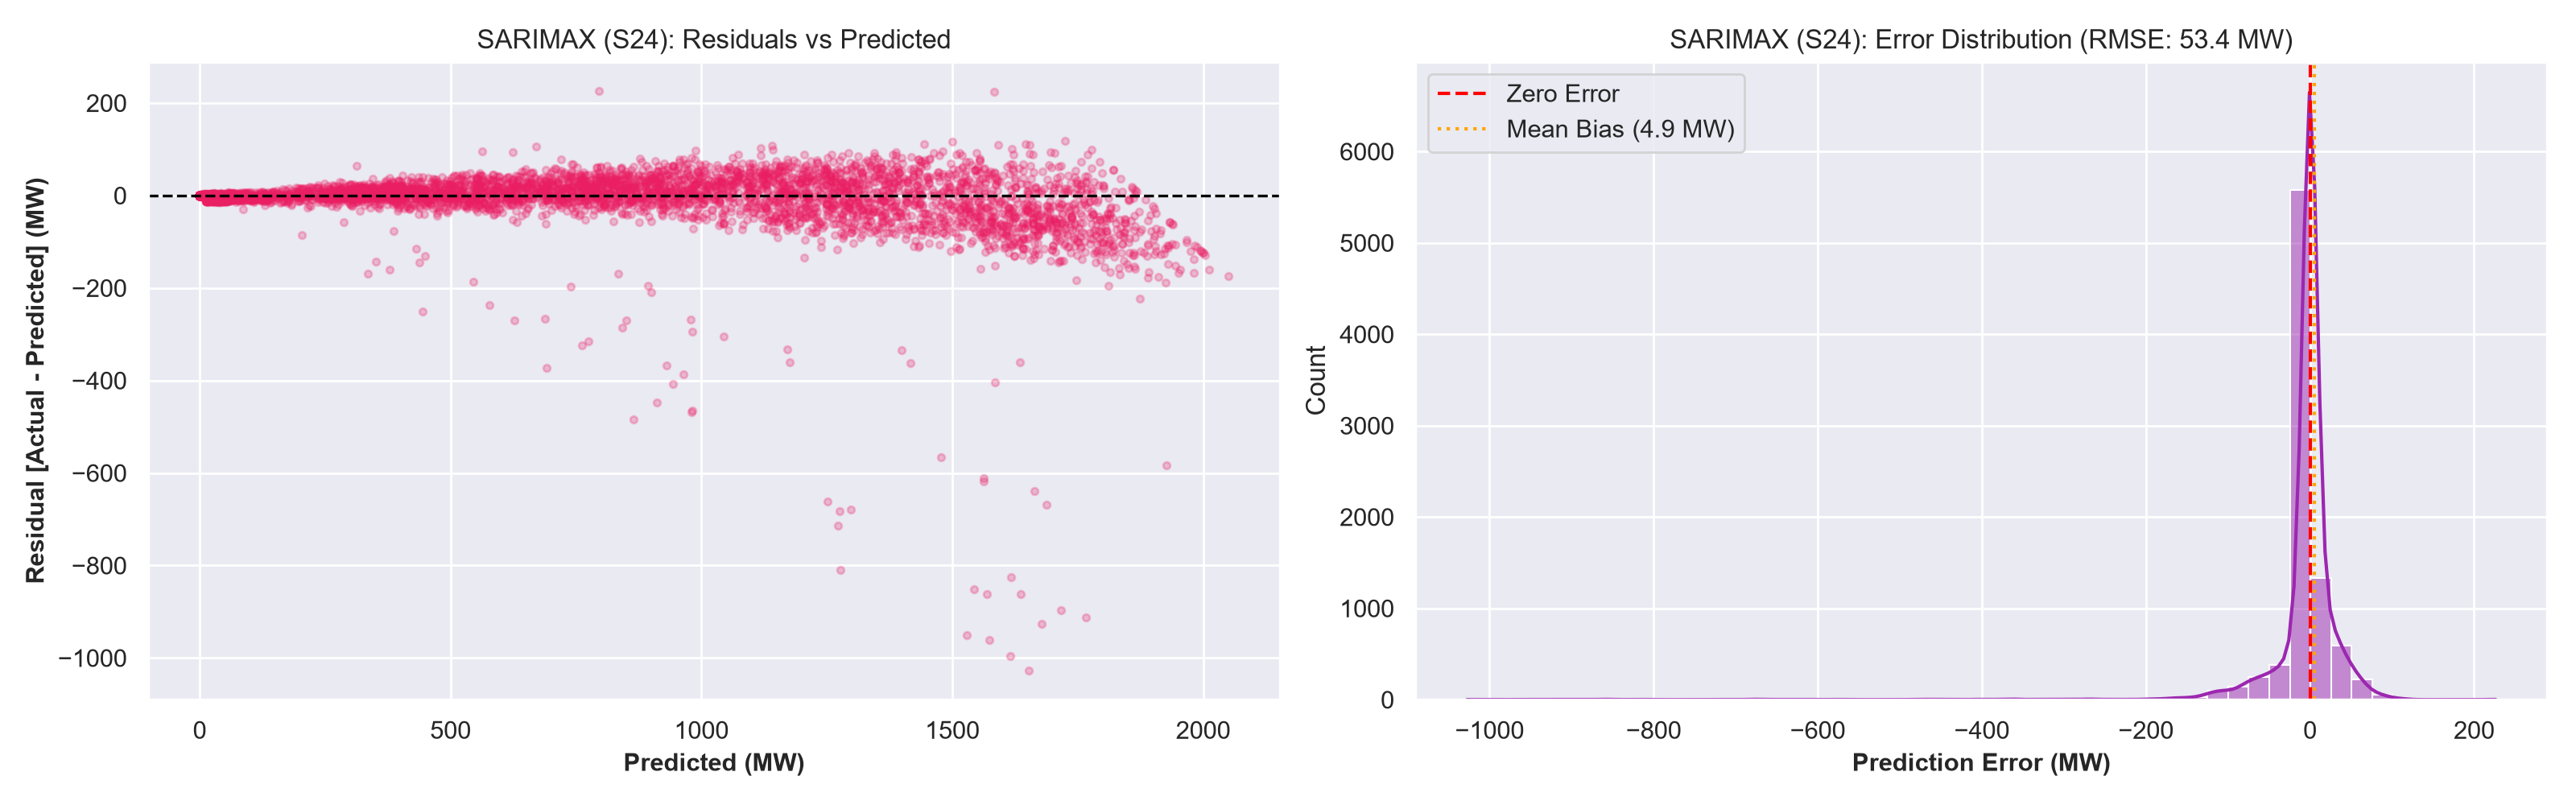

In [4]:
for pid in problems:
    print(f"\n{'='*70}\nDIAGNOSTIC PLOTS FOR PROBLEM {pid}\n{'='*70}")
    fig_actual = config.FIGURES_LINEAR_DIR / f"sarimax_{pid}_actual_vs_predicted.png"
    fig_resid = config.FIGURES_LINEAR_DIR / f"sarimax_{pid}_residuals_distribution.png"
    if fig_actual.exists():
        display(Image(filename=str(fig_actual)))
    if fig_resid.exists():
        display(Image(filename=str(fig_resid)))
